# Dataset insights

Describe what we found in the ECGDeli measurements and AFIB annotations. Run
`01_preprocessing.ipynb` first. This notebook reads data, displays descriptive
results and creates no data files. It does not fit transformations or classifiers.

Full-cohort summaries use all 21,799 ECGs. Associations use the original fixed
10% patient sample (seed 20261008), so they describe a sample rather than
validated model performance.


In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path.cwd().resolve()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / 'src'))
from afib.data_preparation import load_processed_data
from afib.preprocessing import RAW_COLUMNS, CATEGORY_COLUMNS, PARTS, SEED
from afib.evaluation import source_quality_groups

package = load_processed_data(PROJECT / 'processed_data')
raw, targets = package['raw'], package['targets']
y = targets.target_afib
# Global fields are read for source-data descriptions only.
source = package['manifest']['sources']['features']
source_path = PROJECT / source['path']
with source_path.open('rb') as handle:
    assert hashlib.file_digest(handle, 'sha256').hexdigest() == source['sha256']
all_features = pd.read_csv(source_path, index_col='ecg_id').loc[raw.index]
patients = np.sort(targets.patient_id.unique())
sampled = np.random.default_rng(SEED).permutation(patients)[:int(np.ceil(.10 * len(patients)))]
pilot = raw.loc[targets.patient_id.isin(sampled)]
pilot_y = y.loc[pilot.index]
print(f'Full cohort: {len(raw):,} ECGs; descriptive sample: {len(pilot):,} ECGs from {len(sampled):,} patients.')


Full cohort: 21,799 ECGs; descriptive sample: 2,153 ECGs from 1,887 patients.


## 1. Cohort and label balance

There are 1,514 AFIB-labelled ECGs (6.95%) from 18,869 patients. Repeated
recordings require patient-level separation. Predicting no AFIB for every record
would give 93.05% accuracy and miss every AFIB case. A record without the AFIB
label can have other abnormalities.


In [2]:
cohort = pd.Series({
    'ECGs': len(raw), 'Patients': targets.patient_id.nunique(),
    'Recordings beyond one per patient': len(raw) - targets.patient_id.nunique(),
    'AFIB-labelled ECGs': int(y.sum()), 'Other ECGs': int((y == 0).sum()),
    'Source fields': all_features.shape[1], 'Selected lead fields': raw.shape[1],
    'Morphology category fields': len(CATEGORY_COLUMNS),
    'Exact duplicate source feature rows': int(all_features.duplicated().sum()),
})
display(cohort.to_frame('count'))
print(f'AFIB prevalence: {y.mean():.2%}; always-negative accuracy: {1-y.mean():.2%}.')
quality = source_quality_groups(package['metadata'].reset_index())
print(f'Recorded quality issue: {quality.eq("recorded_quality_flag").sum():,} ECGs.')
print('Quality groups are annotation-based; unflagged does not mean verified clean.')


AFIB prevalence: 6.95%; always-negative accuracy: 93.05%.
Recorded quality issue: 5,010 ECGs.
Quality groups are annotation-based; unflagged does not mean verified clean.


,count
ECGs,21799
Patients,18869
Recordings beyond one per patient,2930
AFIB-labelled ECGs,1514
Other ECGs,20285
Source fields,531
Selected lead fields,504
Morphology category fields,24
Exact duplicate source feature rows,0


## 2. Missing measurements

Missingness is concentrated in morphology and ST-elevation fields. Across the
full source table, 10,700 ECGs have at least one gap and 286,584 cells are missing
(2.48%). Among the 504 lead fields, 2.61% of cells are missing; the patient sample
has 2.68%. The table separates full-cohort and sample estimates.

Within the sample, morphology missingness is higher for AFIB-labelled records
(54.60%) than other records (39.80%). Missingness can carry information, but these
associations do not identify why individual measurements are absent.


In [3]:
numerical = [c for c in RAW_COLUMNS if c not in CATEGORY_COLUMNS]
missing = pd.Series({
    'ECGs with any source gap': int(all_features.isna().any(axis=1).sum()),
    'Missing source cells': int(all_features.isna().sum().sum()),
    'Source missing fraction': all_features.isna().to_numpy().mean(),
    'Lead missing fraction': raw.isna().to_numpy().mean(),
    'Numerical lead missing fraction': raw[numerical].isna().to_numpy().mean(),
})
display(missing.to_frame('value'))
field_missing = pd.DataFrame({
    'family': [PARTS[c][0] for c in RAW_COLUMNS],
    'kind': [PARTS[c][2] for c in RAW_COLUMNS],
    'full': raw.isna().mean().to_numpy(),
    'sample': pilot.isna().mean().to_numpy(),
})
family_missing = field_missing.groupby(['family', 'kind'])[['full', 'sample']].mean()
display(family_missing.loc[family_missing.max(axis=1).gt(0)].round(4))
display(pd.DataFrame({
    'ECGs': pilot_y.groupby(pilot_y).size(),
    'mean_missing_fraction': pilot.isna().mean(axis=1).groupby(pilot_y).mean(),
    'morphology_missing_fraction': pilot[CATEGORY_COLUMNS].isna().mean(axis=1).groupby(pilot_y).mean(),
}).rename_axis('AFIB label'))


,value
ECGs with any source gap,10700.000000
Missing source cells,286584.000000
Source missing fraction,0.024758
Lead missing fraction,0.026085
Numerical lead missing fraction,0.007757


full  sample
family     kind                 
PQ_Int     iqr    0.0000  0.0000
           value  0.0000  0.0000
PR_Int     iqr    0.0000  0.0000
           value  0.0000  0.0000
P_Amp      iqr    0.0000  0.0000
           value  0.0000  0.0000
P_DurFull  iqr    0.0000  0.0000
           value  0.0000  0.0000
P_Morph    iqr    0.3926  0.4092
           value  0.3926  0.4092
QRS_Dur    iqr    0.0000  0.0000
           value  0.0000  0.0000
QT_Int     iqr    0.0000  0.0000
           value  0.0000  0.0000
QT_IntCorr iqr    0.0000  0.0000
           value  0.0000  0.0000
Q_Amp      iqr    0.0000  0.0000
           value  0.0000  0.0000
R_Amp      iqr    0.0000  0.0000
           value  0.0000  0.0000
ST_Elev    iqr    0.1550  0.1533
           value  0.1550  0.1533
S_Amp      iqr    0.0000  0.0000
           value  0.0000  0.0000
T_Amp      iqr    0.0000  0.0000
           value  0.0000  0.0000
T_DurFull  iqr    0.0000  0.0000
           value  0.0000  0.0000

,ECGs,mean_missing_fraction,morphology_missing_fraction
AFIB label,,,
0,1990,0.026585,0.397990
1,163,0.029214,0.546012


## 3. Scale and dependence

The fields use different units and include skewed distributions. In the sample,
35 continuous-feature pairs have absolute Spearman correlation of at least 0.90.
The 168 count fields reduce to three distinct sample vectors. These findings
motivate training-only scaling and controlled model complexity; they do not
justify dropping lead identities needed for lead-masking experiments.


Continuous pairs with |Spearman| >= 0.90: 35
168 count fields; 3 distinct sample vectors.


,feature_1,feature_2,spearman
2179,PQ_Int_V1_iqr,PR_Int_V1_iqr,0.984326
2786,PQ_Int_V2_iqr,PR_Int_V2_iqr,0.983352
5174,PQ_Int_V6_iqr,PR_Int_V6_iqr,0.976138
4583,PQ_Int_V5_iqr,PR_Int_V5_iqr,0.974015
2483,PQ_Int_V2,PR_Int_V2,0.973474


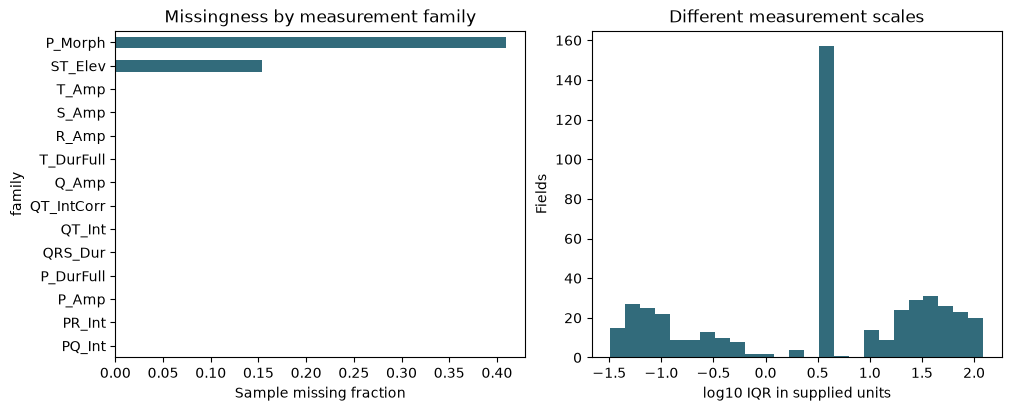

In [4]:
continuous = [c for c in RAW_COLUMNS if PARTS[c][2] != 'count'
              and PARTS[c][0] != 'P_Morph' and pilot[c].nunique() > 1]
corr = pilot[continuous].corr(method='spearman', min_periods=100)
i, j = np.triu_indices(len(continuous), 1)
pairs = pd.DataFrame({
    'feature_1': np.asarray(continuous)[i], 'feature_2': np.asarray(continuous)[j],
    'spearman': corr.to_numpy()[i, j],
}).dropna()
strong_pairs = pairs.loc[pairs.spearman.abs().ge(.90)].copy()
print(f'Continuous pairs with |Spearman| >= 0.90: {len(strong_pairs)}')
display(strong_pairs.sort_values('spearman', key=lambda s: s.abs(), ascending=False).head(5))
counts = [c for c in RAW_COLUMNS if PARTS[c][2] == 'count']
print(f'{len(counts)} count fields; {len(pilot[counts].T.drop_duplicates())} distinct sample vectors.')
iqr = pilot[numerical].quantile(.75) - pilot[numerical].quantile(.25)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
family_missing.xs('value', level='kind')['sample'].sort_values().plot.barh(ax=axes[0], color='#326b7b')
axes[0].set(xlabel='Sample missing fraction', title='Missingness by measurement family')
axes[1].hist(np.log10(iqr[iqr > 0]), bins=25, color='#326b7b')
axes[1].set(xlabel='log10 IQR in supplied units', ylabel='Fields', title='Different measurement scales')
plt.show()


## 4. Association with AFIB

The strongest observed sample association is PR interval IQR in aVR
(Spearman correlation 0.408). It motivates testing variability features. It is
not an estimate of out-of-sample predictive importance.


In [5]:
from scipy.stats import spearmanr
associations = []
for name in numerical:
    observed = pilot[name].notna()
    if observed.sum() >= 100 and pilot.loc[observed, name].nunique() > 1:
        rho = spearmanr(pilot.loc[observed, name], pilot_y.loc[observed]).statistic
        associations.append({'feature': name, 'n_observed': int(observed.sum()), 'spearman_with_AFIB': rho})
association_table = pd.DataFrame(associations).sort_values(
    'spearman_with_AFIB', key=lambda s: s.abs(), ascending=False)
display(association_table.head(5).round(3))


,feature,n_observed,spearman_with_AFIB
70,PR_Int_aVR_iqr,2153,0.408
34,PQ_Int_aVR_iqr,2153,0.403
40,PR_Int_II_iqr,2153,0.398
4,PQ_Int_II_iqr,2153,0.393
64,PR_Int_aVF_iqr,2153,0.379


## What these findings establish

The dataset has class imbalance, repeated patients, concentrated missingness,
unequal scales and correlated measurements. These are descriptive findings.
The project plan defines the experiments needed to learn whether feature
construction, augmentation or learned filling improves AFIB classification.
No classifier benefit has been measured yet.

Sources: PTB-XL+ 1.0.1 ECGDeli features and PTB-XL 1.0.3 annotations. The
source hashes are recorded in `processed_data/manifest.json`. See
`docs/Data_Insights.docx` for the concise written interpretation.
